# Análisis Exploratorio de Datos (EDA) y Preprocesamiento

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')


## 1. Descripción general del dataset e Identificación de Variables


In [2]:
# Ruta desde la raiz del proyecto
ruta_excel = Path('../data/raw/base_datos.xlsx')

# Leer el archivo
try:
    df = pd.read_excel(ruta_excel)
except FileNotFoundError:
    print('Archivo no encontrado. Asegúrese de que la ruta sea correcta o cargue el dataframe en memoria.')
    # Para visualización del notebook crearemos un df dummy si falla la carga
    # df = pd.DataFrame(...) 

df.info()
df.head()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10763 entries, 0 to 10762
Data columns (total 23 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   tipo_credito                   10763 non-null  int64         
 1   fecha_prestamo                 10763 non-null  datetime64[ns]
 2   capital_prestado               10763 non-null  float64       
 3   plazo_meses                    10763 non-null  int64         
 4   edad_cliente                   10763 non-null  int64         
 5   tipo_laboral                   10763 non-null  object        
 6   salario_cliente                10763 non-null  int64         
 7   total_otros_prestamos          10763 non-null  int64         
 8   cuota_pactada                  10763 non-null  int64         
 9   puntaje                        10763 non-null  float64       
 10  puntaje_datacredito            10757 non-null  float64       
 11  cant_creditosvi

,tipo_credito,fecha_prestamo,capital_prestado,plazo_meses,edad_cliente,tipo_laboral,salario_cliente,total_otros_prestamos,cuota_pactada,puntaje,...,saldo_mora,saldo_total,saldo_principal,saldo_mora_codeudor,creditos_sectorFinanciero,creditos_sectorCooperativo,creditos_sectorReal,promedio_ingresos_datacredito,tendencia_ingresos,Pago_atiempo
0,4,2025-01-07 14:40:36,1852560.0,12,32,Empleado,3500000,1000000,128650,95.227787,...,0.0,0.0,NaN,NaN,0,0,0,916148.0,Creciente,1
1,4,2025-01-09 11:18:48,3181080.0,6,34,Empleado,5000000,2000000,441817,95.227787,...,0.0,0.0,NaN,NaN,0,0,0,4473774.0,Creciente,1
2,9,2024-12-26 18:52:57,670200.0,5,34,Independiente,5000000,2000000,108632,95.227787,...,0.0,274561.0,274561.0,NaN,2,0,1,NaN,NaN,1
3,9,2024-12-04 14:20:50,506806.8,2,25,Independiente,3000000,900000,199684,95.227787,...,0.0,27564.0,27564.0,NaN,1,0,6,NaN,NaN,1
4,4,2025-04-30 18:41:57,999780.0,10,26,Empleado,2000000,600000,92509,95.227787,...,0.0,0.0,NaN,NaN,0,0,0,61000.0,Creciente,1


### Clasificación de Variables
- **Numéricas Continuas**: `capital_prestado`, `salario_cliente`, `saldo_total`, `promedio_ingresos_datacredito`, etc.
- **Numéricas Discretas**: `plazo_meses`, `edad_cliente`, `cant_creditosvigentes`, `huella_consulta`.
- **Categóricas**: `tipo_laboral`, `tendencia_ingresos`.
- **Fechas**: `fecha_prestamo`.
- **Binarias/Booleanas**: `Pago_atiempo`, y `saldo_mora` (una vez transformada).


### 1.1 Calidad inicial: duplicados y variable objetivo
Antes de limpiar, se revisa si hay filas repetidas y cómo se distribuye `Pago_atiempo` (balance de clases).

In [3]:
# Duplicados (solo se reporta; no se eliminan automáticamente)
n_dup = df.duplicated().sum()
print(f'Filas duplicadas exactas: {n_dup} ({n_dup / len(df) * 100:.2f}%)')
if n_dup > 0:
    display(df[df.duplicated(keep=False)].sort_values(list(df.columns[:3])).head(10))

Filas duplicadas exactas: 0 (0.00%)


,registros,porcentaje (%)
Pago_atiempo,,
0,511,4.75
1,10252,95.25


Razón clase mayoritaria / minoritaria: 20.1 a 1


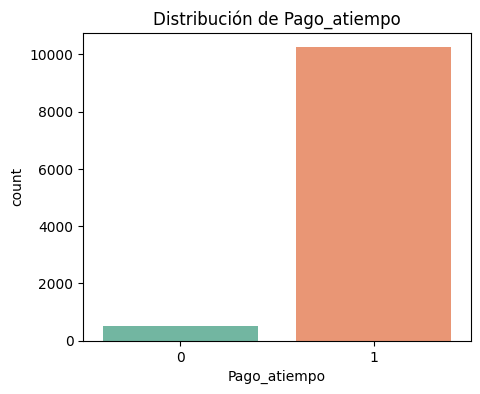

In [4]:
# Distribución de la variable objetivo
conteo = df['Pago_atiempo'].value_counts().sort_index()
porcentaje = (df['Pago_atiempo'].value_counts(normalize=True).sort_index() * 100).round(2)
display(pd.DataFrame({'registros': conteo, 'porcentaje (%)': porcentaje}))

razon = conteo.max() / conteo.min()
print(f'Razón clase mayoritaria / minoritaria: {razon:.1f} a 1')

plt.figure(figsize=(5, 4))
sns.countplot(x='Pago_atiempo', data=df, palette='Set2')
plt.title('Distribución de Pago_atiempo')
plt.show()

**Nota para el modelado:** si la clase minoritaria es pequeña, hay desbalance. Conviene usar `train_test_split(..., stratify=y)` y evaluar con métricas distintas a la exactitud (recall, F1, AUC-PR).

## 2. Limpieza de Datos: Columnas irrelevantes y Tratamiento de Nulos
Se eliminan variables con alta multicolinealidad y se unifica la representación de los valores nulos.


Revisamos la matriz de correlacion y se encontro que algunas columnas de datos tenian una correlacion muy alta, y lo mas recomendable es excluir estas variables ya que presentarian problemas de alta multicolinealidad, (Redundancia de informacion) o posible fuga de datos 

Se eliminaran las variables:

puntaje
creditos_sectorFinanciero
cuota_pactada
saldo_principal
saldo_mora_codeudor

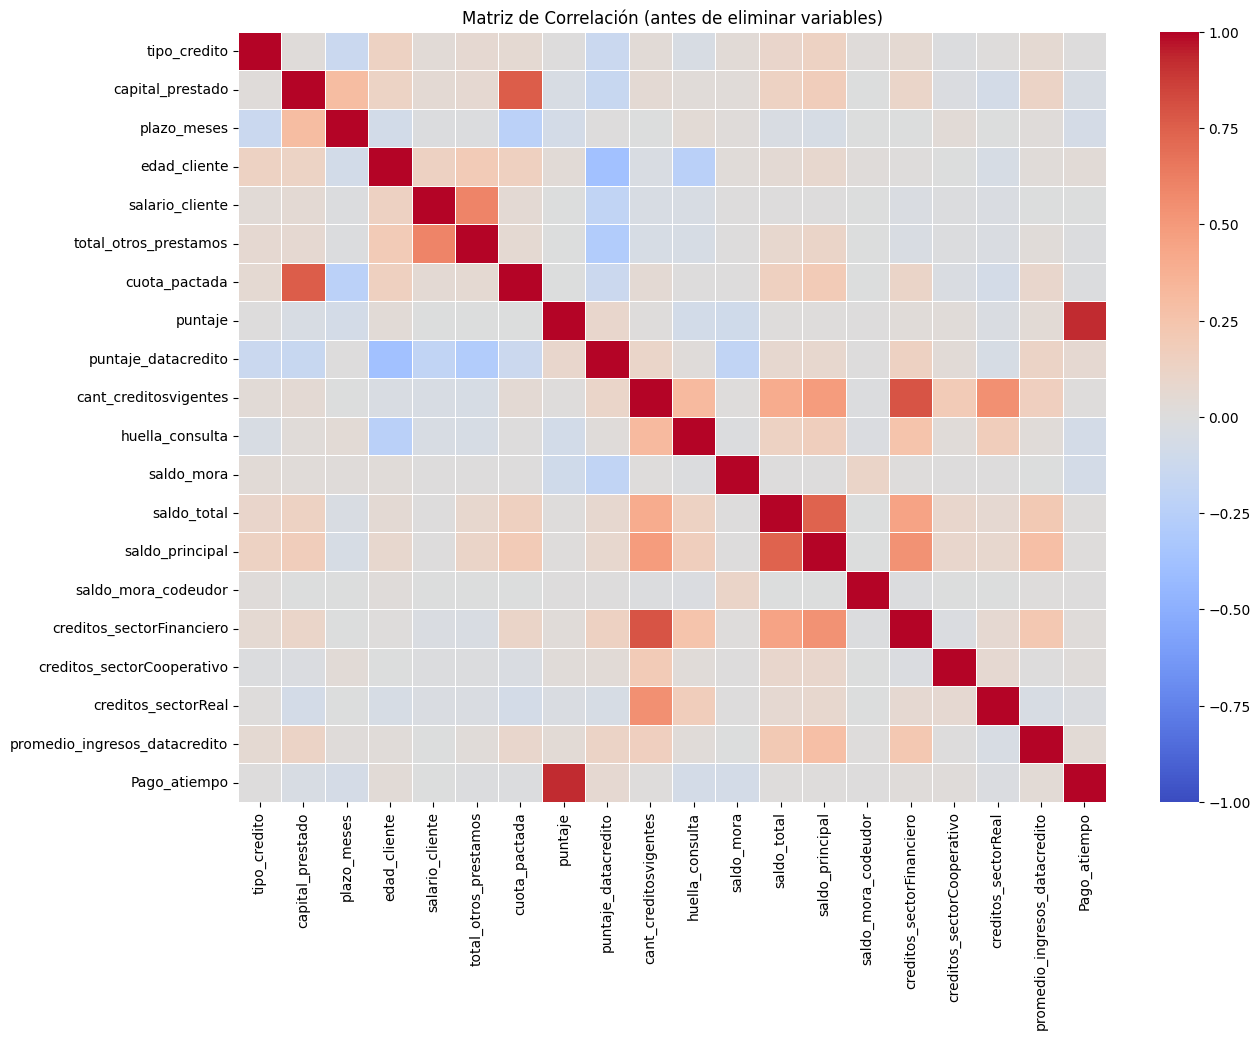

,,correlacion
puntaje,Pago_atiempo,0.923134


In [5]:
# Evidencia para la eliminación de variables: pares con correlación alta (ANTES de eliminar)
corr_inicial = df.corr(numeric_only=True)

plt.figure(figsize=(14, 10))
sns.heatmap(corr_inicial, annot=False, cmap='coolwarm', linewidths=0.5, vmin=-1, vmax=1)
plt.title('Matriz de Correlación (antes de eliminar variables)')
plt.show()

# Pares con |correlación| > 0.8 (triángulo superior para no repetir)
mask = np.triu(np.ones(corr_inicial.shape, dtype=bool), k=1)
pares = corr_inicial.where(mask).stack()
pares_altos = pares[pares.abs() > 0.8].sort_values(key=abs, ascending=False)
display(pares_altos.rename('correlacion').to_frame())

In [6]:
# Eliminación de variables irrelevantes
columnas_a_eliminar = ['puntaje', 'creditos_sectorFinanciero', 'cuota_pactada', 'saldo_principal', 'saldo_mora_codeudor']
df = df.drop(columns=[col for col in columnas_a_eliminar if col in df.columns])


In [7]:
# Revisión inicial de nulos
print('Valores nulos antes del tratamiento:')
print(df.isnull().sum())


Valores nulos antes del tratamiento:
tipo_credito                        0
fecha_prestamo                      0
capital_prestado                    0
plazo_meses                         0
edad_cliente                        0
tipo_laboral                        0
salario_cliente                     0
total_otros_prestamos               0
puntaje_datacredito                 6
cant_creditosvigentes               0
huella_consulta                     0
saldo_mora                        156
saldo_total                       156
creditos_sectorCooperativo          0
creditos_sectorReal                 0
promedio_ingresos_datacredito    2930
tendencia_ingresos               2932
Pago_atiempo                        0
dtype: int64


In [8]:
# Evidencia para convertir puntaje_datacredito a entero: ¿hay decimales reales?
serie_sin_nulos = df['puntaje_datacredito'].dropna()
con_decimales = serie_sin_nulos[serie_sin_nulos % 1 != 0]
print('Registros con decimales reales:', len(con_decimales))
print('Nulos que se eliminarán:', df['puntaje_datacredito'].isnull().sum())
print(f"Porcentaje de nulos: {df['puntaje_datacredito'].isnull().mean() * 100:.3f}%")
display(df['puntaje_datacredito'].value_counts().head(10))

Registros con decimales reales: 0
Nulos que se eliminarán: 6
Porcentaje de nulos: 0.056%


puntaje_datacredito
0.0      145
802.0    102
783.0    102
791.0    100
804.0     98
801.0     98
769.0     95
796.0     93
814.0     92
792.0     91
Name: count, dtype: int64

In [9]:
# 1. Puntaje Datacredito: Eliminar 6 nulos y convertir a entero
# revisando los datos que tiene mi columna de puntaje datacredito, encontramos que algunos de estos son de tipo float los cuales no tienen ningun valor decimal real, ent se decidio convertir a tipo entero toda la columna, pero para poder hacer esto, se encontro que habian 6 valores nulos, los cuales NO podemos asignarles un valor como 0, ya que tambien esta el puntaje 0, ent asi se decidio eliminar a estos 6 registros, ya que es un porcentaje menor al 0.06% de los datos
df = df.dropna(subset=['puntaje_datacredito'])
df['puntaje_datacredito'] = df['puntaje_datacredito'].astype(int)

# 2. Saldo Mora: Rellenar con 0 y convertir a formato binario (1 si > 0, 0 si no)
# Para la columna saldo_mora se identifico que mas de 10.000 de los datos contenian el valor 0, y los demas eran numeros dispersos, frente a esto se tomo la decision de convertir la variable saldo_mora a tipo binario, 156 valores nulos los asignamos como que no tenian saldo en mora, ya que no afectaban en la generacion del modelo y ademas se podia interpretar como la ausencia al igual que el 0 de saldo en mora, despues los demas valores que eran diferentes y mayores a 0, lo que significaba que si habia saldo en mora, les asignamos un valor de 1, a pesar de que solo eran 55 registros los cuales tenian un saldo en mora se evidencio que el tener un saldo en mora aumentaba drasticamente si si pagaban a tiempo, pasando de 4.58% de imcumplir su pago teniendo el saldo en mora en 0, a 36.36% de incumplir su pago teniendo su saldo en mora en 1 
df['saldo_mora'] = df['saldo_mora'].fillna(0)
df['saldo_mora'] = (df['saldo_mora'] > 0).astype(int)

# 3. Saldo Total: Imputar nulos con la media
# Los 150 registros nulos de la comuna saldo total se rellenaron con la media (promedio de los datos) para asi no generar una desviacion o sesgo en el modelo
df['saldo_total'] = df['saldo_total'].fillna(df['saldo_total'].mean())

# 4. Promedio Ingresos Datacredito: Imputar nulos con la media
# Con los 2.925 datos nulos de la columna, si los eliminabamos generaba un gran porcentaje de perdida de datos, ent revisando se opto por inputar los valores nulos con la media (promedio de los datos) de los datos 
if 'promedio_ingresos_datacredito' in df.columns:
    df['promedio_ingresos_datacredito'] = df['promedio_ingresos_datacredito'].fillna(df['promedio_ingresos_datacredito'].mean())

# 5. Tendencia Ingresos: Filtrar atípicos y rellenar con la moda
# Se evidencio que en los datos de la columna habian datos atipicos com numericos, 57 eran numericos, y el resto que eran al rededor de 2.900 a 3.000, y esos nulos se llenaron con la moda
if 'tendencia_ingresos' in df.columns:
    categorias_validas = ['Creciente', 'Decreciente', 'Estable']
    df.loc[~df['tendencia_ingresos'].isin(categorias_validas), 'tendencia_ingresos'] = np.nan
    moda_tendencia = df['tendencia_ingresos'].mode()[0]
    df['tendencia_ingresos'] = df['tendencia_ingresos'].fillna(moda_tendencia)


### Verificación del tratamiento de nulos

In [10]:
# Nulos restantes y tipos de dato tras el tratamiento
nulos = df.isnull().sum()
print('Columnas con nulos restantes:')
print(nulos[nulos > 0] if (nulos > 0).any() else 'Ninguna')
print()
print('puntaje_datacredito ->', df['puntaje_datacredito'].dtype)
print('Valores de saldo_mora:', sorted(df['saldo_mora'].unique()))
print()
print('tendencia_ingresos:')
display(df['tendencia_ingresos'].value_counts())
print()
df.info()

Columnas con nulos restantes:
Ninguna

puntaje_datacredito -> int64
Valores de saldo_mora: [np.int64(0), np.int64(1)]

tendencia_ingresos:


tendencia_ingresos
Creciente      8278
Decreciente    1291
Estable        1188
Name: count, dtype: int64


<class 'pandas.core.frame.DataFrame'>
Index: 10757 entries, 0 to 10762
Data columns (total 18 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   tipo_credito                   10757 non-null  int64         
 1   fecha_prestamo                 10757 non-null  datetime64[ns]
 2   capital_prestado               10757 non-null  float64       
 3   plazo_meses                    10757 non-null  int64         
 4   edad_cliente                   10757 non-null  int64         
 5   tipo_laboral                   10757 non-null  object        
 6   salario_cliente                10757 non-null  int64         
 7   total_otros_prestamos          10757 non-null  int64         
 8   puntaje_datacredito            10757 non-null  int64         
 9   cant_creditosvigentes          10757 non-null  int64         
 10  huella_consulta                10757 non-null  int64         
 11  saldo_mora         

In [11]:
# Respaldo de la decisión sobre saldo_mora: relación con Pago_atiempo (% por fila)
tabla_pct = (pd.crosstab(df['saldo_mora'], df['Pago_atiempo'], normalize='index') * 100).round(2)
tabla_n = pd.crosstab(df['saldo_mora'], df['Pago_atiempo'])
print('Porcentaje por categoría de saldo_mora:')
display(tabla_pct)
print('Número de registros:')
display(tabla_n)

Porcentaje por categoría de saldo_mora:


Pago_atiempo,0,1
saldo_mora,,
0,4.58,95.42
1,36.36,63.64


Número de registros:


Pago_atiempo,0,1
saldo_mora,,
0,490,10212
1,20,35


## 3. Conversión de Tipos y Corrección de Inconsistencias


In [12]:
df['fecha_prestamo'] = pd.to_datetime(df['fecha_prestamo'], errors='coerce')

if 'tipo_credito' in df.columns:
    conteos = df['tipo_credito'].value_counts()
    categorias_minoritarias = conteos[conteos < 50].index
    df['tipo_credito'] = df['tipo_credito'].replace(categorias_minoritarias, 'Otros')
    df = pd.get_dummies(df, columns=['tipo_credito'], dtype=int)


In [13]:
# Revisión de la conversión de fechas (errors='coerce' puede generar NaT sin avisar)
n_nat = df['fecha_prestamo'].isna().sum()
print(f'Fechas no válidas (NaT): {n_nat}')
print('Rango de fechas:', df['fecha_prestamo'].min(), '->', df['fecha_prestamo'].max())

# Columnas que siguen como texto y habrá que codificar antes de modelar
print('\nColumnas tipo texto pendientes de codificar:', df.select_dtypes(include='object').columns.tolist())

Fechas no válidas (NaT): 0
Rango de fechas: 2024-11-26 09:17:04 -> 2026-04-26 18:43:52

Columnas tipo texto pendientes de codificar: ['tipo_laboral', 'tendencia_ingresos']


## 4. Reglas de Validación de Datos y Atributos Derivados
- **Validaciones**: Verificar que los salarios no sean negativos y las edades sean lógicas.
- **Atributo Calculado**: Ratio de deuda vs ingresos, una métrica clave en riesgo crediticio.


In [43]:
# Reglas de validación: cada regla cuenta los registros que la incumplen
reglas = {
    'salario_cliente < 0':               (df['salario_cliente'] < 0).sum(),
    'salario_cliente == 0':              (df['salario_cliente'] == 0).sum(),
    'edad_cliente fuera de 18-100':      (~df['edad_cliente'].between(18, 100)).sum(),
    'capital_prestado <= 0':             (df['capital_prestado'] <= 0).sum(),
    'plazo_meses <= 0':                  (df['plazo_meses'] <= 0).sum(),
    'total_otros_prestamos < 0':         (df['total_otros_prestamos'] < 0).sum(),
    'cant_creditosvigentes < 0':         (df['cant_creditosvigentes'] < 0).sum(),
    'huella_consulta < 0':               (df['huella_consulta'] < 0).sum(),
    'fecha_prestamo nula (NaT)':         df['fecha_prestamo'].isna().sum(),
    'fecha_prestamo en el futuro':       (df['fecha_prestamo'] > pd.Timestamp.today()).sum(),
}
resultado = pd.DataFrame({'registros que incumplen': pd.Series(reglas)})
resultado['% del total'] = (resultado['registros que incumplen'] / len(df) * 100).round(3)
display(resultado)

print('Rango de puntaje_datacredito:', df['puntaje_datacredito'].min(), '-', df['puntaje_datacredito'].max())

,registros que incumplen,% del total
salario_cliente < 0,0,0.000
salario_cliente == 0,24,0.226
edad_cliente fuera de 18-100,0,0.000
capital_prestado <= 0,0,0.000
plazo_meses <= 0,0,0.000
total_otros_prestamos < 0,0,0.000
cant_creditosvigentes < 0,0,0.000
huella_consulta < 0,0,0.000
fecha_prestamo nula (NaT),0,0.000
fecha_prestamo en el futuro,0,0.000


Rango de puntaje_datacredito: -7 - 999


In [42]:
# Filtrar el DataFrame para conservar solo clientes con edades lógicas (entre 18 y 100)
df = df[df['edad_cliente'].between(18, 100)]

# Verificación de la limpieza
print(f"Registros restantes: {len(df)}")
print(f"Rango de edad actual: {df['edad_cliente'].min()} a {df['edad_cliente'].max()} años")

Registros restantes: 10610
Rango de edad actual: 19 a 69 años


In [15]:
# Atributo Derivado: Ratio Deuda-Ingreso
# Evitamos divisiones por cero
df['ratio_deuda_ingreso'] = np.where(df['salario_cliente'] > 0, 
                                     df['total_otros_prestamos'] / df['salario_cliente'], 0)


## 5. Estadística Descriptiva Post-Ajustes y Distribuciones
Se ejecuta describe() tras asegurar que los tipos de datos son los correctos.


In [16]:
print('--- Resumen Estadístico ---')
display(df.describe())

print('\n--- Varianza ---')
display(df.var(numeric_only=True))

print('\n--- Skewness (Asimetría) ---')
display(df.skew(numeric_only=True))

print('\n--- Kurtosis ---')
display(df.kurt(numeric_only=True))


--- Resumen Estadístico ---


,fecha_prestamo,capital_prestado,plazo_meses,edad_cliente,salario_cliente,total_otros_prestamos,puntaje_datacredito,cant_creditosvigentes,huella_consulta,saldo_mora,saldo_total,creditos_sectorCooperativo,creditos_sectorReal,promedio_ingresos_datacredito,Pago_atiempo,tipo_credito_4,tipo_credito_9,tipo_credito_10,tipo_credito_Otros,ratio_deuda_ingreso
count,10757,1.075700e+04,10757.000000,10757.000000,1.075700e+04,1.075700e+04,10757.000000,10757.000000,10757.000000,10757.000000,1.075700e+04,10757.000000,10757.000000,1.075700e+04,10757.000000,10757.000000,10757.000000,10757.000000,10757.000000,10757.000000
mean,2025-04-16 23:27:25.843264768,2.433723e+06,10.576369,43.930092,1.718214e+07,6.207703e+06,780.790834,5.729943,4.230919,0.005113,4.593741e+04,0.269964,1.303430,2.005291e+06,0.952589,0.719996,0.266989,0.010784,0.002231,0.683815
min,2024-11-26 09:17:04,3.600000e+05,2.000000,19.000000,0.000000e+00,0.000000e+00,-7.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2025-01-20 17:30:54,1.224742e+06,6.000000,33.000000,2.000000e+06,5.000000e+05,757.000000,3.000000,2.000000,0.000000,3.024000e+03,0.000000,0.000000,9.618850e+05,1.000000,0.000000,0.000000,0.000000,0.000000,0.208333
50%,2025-03-27 16:27:27,1.921482e+06,10.000000,42.000000,3.000000e+06,1.000000e+06,791.000000,5.000000,4.000000,0.000000,1.674100e+04,0.000000,1.000000,1.834902e+06,1.000000,1.000000,0.000000,0.000000,0.000000,0.333333
75%,2025-06-16 13:58:03,3.084000e+06,12.000000,53.000000,4.848000e+06,2.000000e+06,825.000000,8.000000,6.000000,0.000000,5.217300e+04,0.000000,2.000000,2.005291e+06,1.000000,1.000000,1.000000,0.000000,0.000000,0.475000
max,2026-04-26 18:43:52,4.144415e+07,90.000000,123.000000,2.200000e+10,6.787675e+09,999.000000,62.000000,29.000000,1.000000,5.116066e+06,13.000000,25.000000,3.810658e+07,1.000000,1.000000,1.000000,1.000000,1.000000,2439.000000
std,NaN,1.909595e+06,6.633604,15.007019,3.555566e+08,1.184043e+08,104.878031,3.975970,3.063910,0.071325,1.055262e+05,0.716642,1.824679,1.829585e+06,0.212526,0.449022,0.442407,0.103288,0.047184,24.057791



--- Varianza ---


capital_prestado                 3.646553e+12
plazo_meses                      4.400470e+01
edad_cliente                     2.252106e+02
salario_cliente                  1.264205e+17
total_otros_prestamos            1.401957e+16
puntaje_datacredito              1.099940e+04
cant_creditosvigentes            1.580834e+01
huella_consulta                  9.387541e+00
saldo_mora                       5.087280e-03
saldo_total                      1.113578e+10
creditos_sectorCooperativo       5.135762e-01
creditos_sectorReal              3.329454e+00
promedio_ingresos_datacredito    3.347381e+12
Pago_atiempo                     4.516739e-02
tipo_credito_4                   2.016204e-01
tipo_credito_9                   1.957240e-01
tipo_credito_10                  1.066838e-02
tipo_credito_Otros               2.226334e-03
ratio_deuda_ingreso              5.787773e+02
dtype: float64


--- Skewness (Asimetría) ---


capital_prestado                  3.726487
plazo_meses                       2.459076
edad_cliente                      1.921743
salario_cliente                  43.771730
total_otros_prestamos            38.497518
puntaje_datacredito              -5.644513
cant_creditosvigentes             1.799616
huella_consulta                   1.488216
saldo_mora                       13.879506
saldo_total                      20.339946
creditos_sectorCooperativo        4.217392
creditos_sectorReal               3.164342
promedio_ingresos_datacredito     5.015571
Pago_atiempo                     -4.259928
tipo_credito_4                   -0.980074
tipo_credito_9                    1.053574
tipo_credito_10                   9.474634
tipo_credito_Otros               21.102956
ratio_deuda_ingreso              97.659697
dtype: float64


--- Kurtosis ---


capital_prestado                   35.346872
plazo_meses                         7.775033
edad_cliente                        7.840062
salario_cliente                  2210.491243
total_otros_prestamos            1721.094178
puntaje_datacredito                39.437798
cant_creditosvigentes               8.635597
huella_consulta                     4.003353
saldo_mora                        190.676132
saldo_total                       800.363952
creditos_sectorCooperativo         29.334989
creditos_sectorReal                18.182264
promedio_ingresos_datacredito      46.117448
Pago_atiempo                       16.149991
tipo_credito_4                     -1.039648
tipo_credito_9                     -0.890147
tipo_credito_10                    87.785016
tipo_credito_Otros                443.417207
ratio_deuda_ingreso              9830.183386
dtype: float64

### Tipo de Distribución
Al observar el **Skewness**: valores cercanos a 0 indican distribución normal, > 0 asimetría positiva (cola a la derecha, común en salarios/capital), < 0 asimetría negativa.


## 6. Análisis Univariado: Histogramas y Boxplots para Variables Numéricas


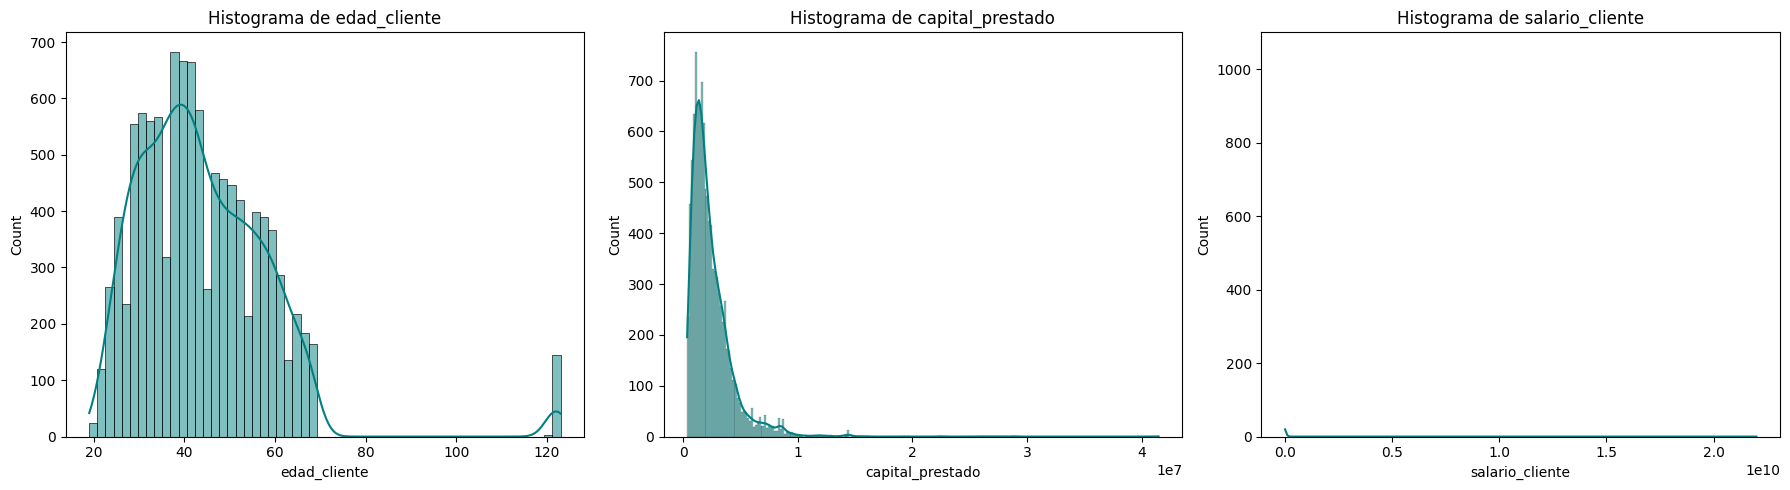

In [17]:
cols_num = ['edad_cliente', 'capital_prestado', 'salario_cliente']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, col in enumerate(cols_num):
    sns.histplot(df[col].dropna(), kde=True, ax=axes[i], color='teal')
    axes[i].set_title(f'Histograma de {col}')
plt.tight_layout()
plt.show()


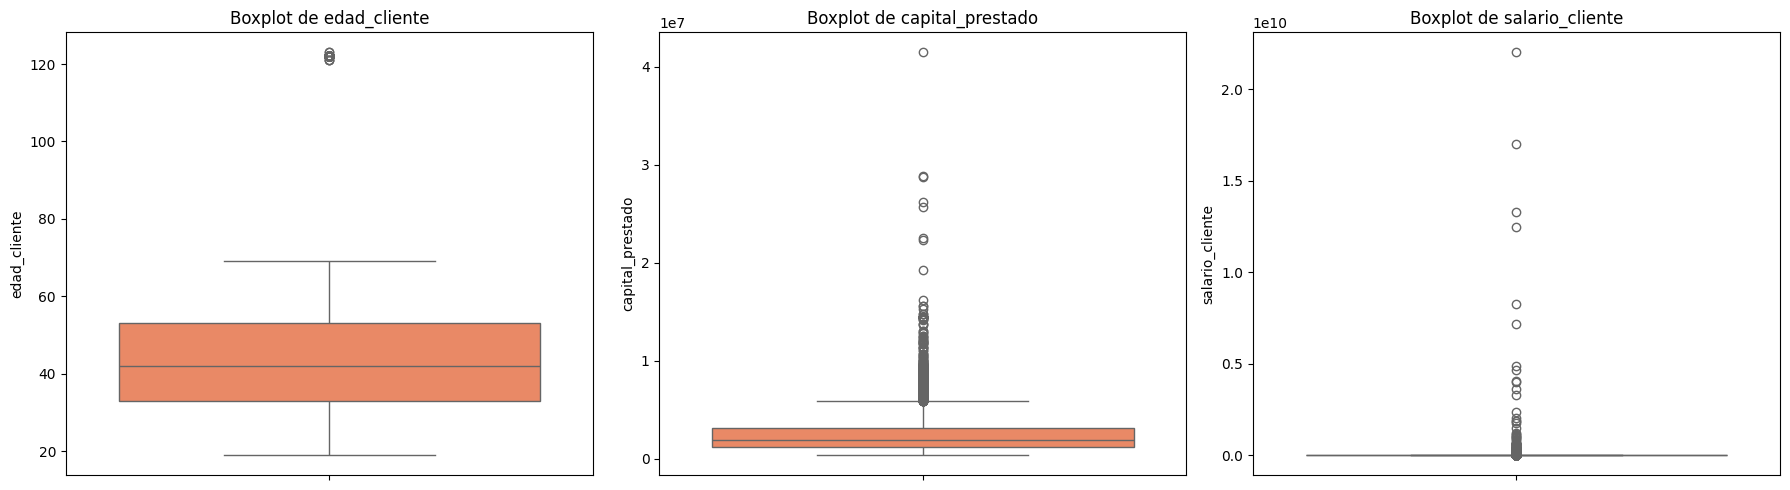

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, col in enumerate(cols_num):
    sns.boxplot(y=df[col].dropna(), ax=axes[i], color='coral')
    axes[i].set_title(f'Boxplot de {col}')
plt.tight_layout()
plt.show()


### Variables numéricas restantes
Nota: `saldo_total` y `promedio_ingresos_datacredito` fueron imputadas con la media, por eso se puede ver un pico en ese valor.

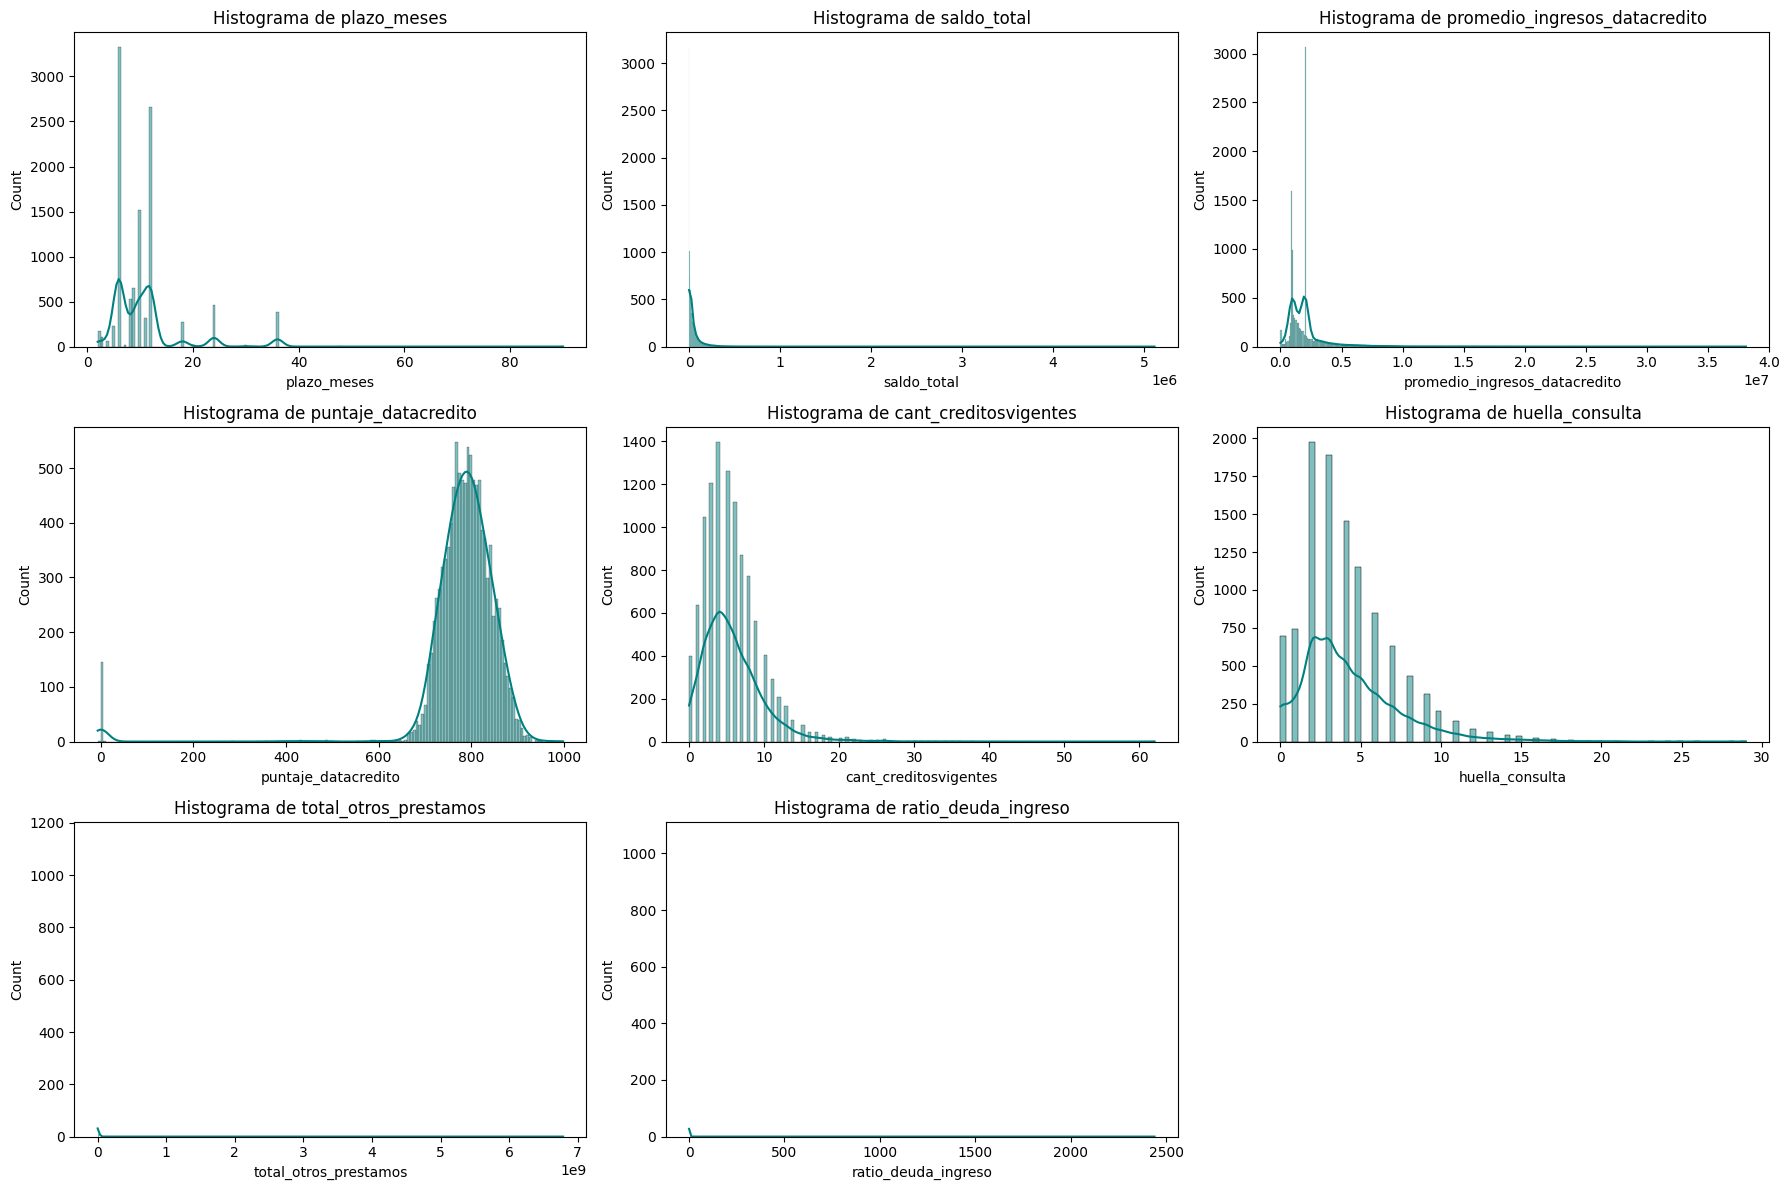

In [19]:
def grafica_en_grilla(cols, tipo, ncols=3):
    nrows = -(-len(cols) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 4 * nrows))
    axes = np.array(axes).ravel()
    for ax, col in zip(axes, cols):
        if tipo == 'hist':
            sns.histplot(df[col].dropna(), kde=True, ax=ax, color='teal')
            ax.set_title(f'Histograma de {col}')
        else:
            sns.boxplot(y=df[col].dropna(), ax=ax, color='coral')
            ax.set_title(f'Boxplot de {col}')
    for ax in axes[len(cols):]:
        ax.axis('off')
    plt.tight_layout()
    plt.show()

cols_extra = [c for c in ['plazo_meses', 'saldo_total', 'promedio_ingresos_datacredito',
                          'puntaje_datacredito', 'cant_creditosvigentes', 'huella_consulta',
                          'total_otros_prestamos', 'ratio_deuda_ingreso'] if c in df.columns]
grafica_en_grilla(cols_extra, 'hist')

In [ ]:
grafica_en_grilla(cols_extra, 'box')

## 7. Variables Categóricas: Countplot, Value Counts y Tablas Pivote


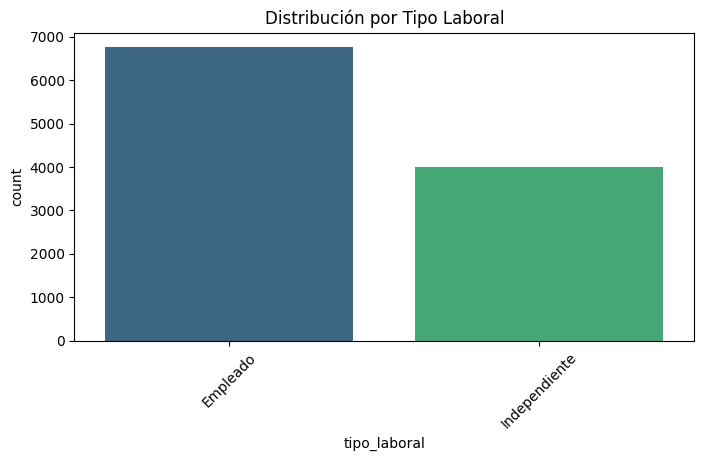


Conteo de Valores (value_counts) para Tipo Laboral:


tipo_laboral
Empleado         6750
Independiente    4007
Name: count, dtype: int64


Tabla Pivote (Capital promedio y máximo por tipo laboral):


,mean,max,count
,capital_prestado,capital_prestado,capital_prestado
tipo_laboral,,,
Empleado,2.394036e+06,41444152.8,6750
Independiente,2.500577e+06,15600000.0,4007


In [20]:
if 'tipo_laboral' in df.columns:
    plt.figure(figsize=(8, 4))
    sns.countplot(x='tipo_laboral', data=df, palette='viridis')
    plt.title('Distribución por Tipo Laboral')
    plt.xticks(rotation=45)
    plt.show()
    
    print('\nConteo de Valores (value_counts) para Tipo Laboral:')
    display(df['tipo_laboral'].value_counts())
    
    print('\nTabla Pivote (Capital promedio y máximo por tipo laboral):')
    display(pd.pivot_table(df, values='capital_prestado', index='tipo_laboral', aggfunc=['mean', 'max', 'count']))


--- tipo_laboral ---


,registros,tasa_pago_atiempo,% del total
tipo_laboral,,,
Empleado,6750,95.72,62.75
Independiente,4007,94.48,37.25


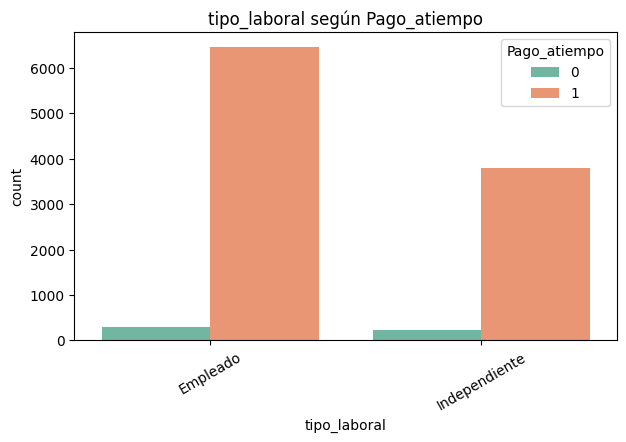

--- tendencia_ingresos ---


,registros,tasa_pago_atiempo,% del total
tendencia_ingresos,,,
Creciente,8278,95.48,76.95
Decreciente,1291,93.73,12.00
Estable,1188,95.37,11.04


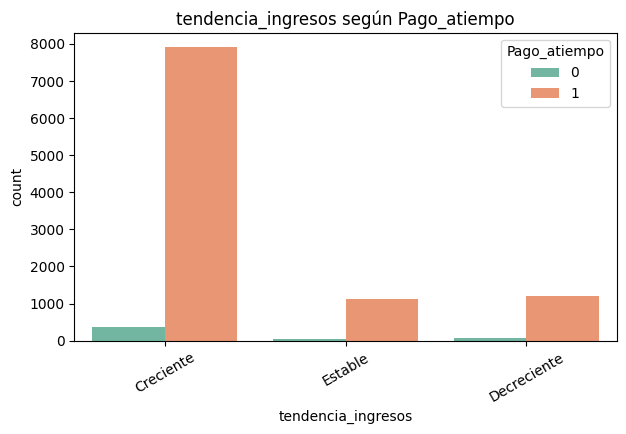

In [21]:
# Categóricas vs objetivo: distribución y tasa de Pago_atiempo (promedio) por categoría
for col in ['tipo_laboral', 'tendencia_ingresos']:
    print(f'--- {col} ---')
    resumen = df.groupby(col)['Pago_atiempo'].agg(registros='count', tasa_pago_atiempo='mean')
    resumen['% del total'] = (resumen['registros'] / len(df) * 100).round(2)
    resumen['tasa_pago_atiempo'] = (resumen['tasa_pago_atiempo'] * 100).round(2)
    display(resumen)

    plt.figure(figsize=(7, 4))
    sns.countplot(x=col, data=df, hue='Pago_atiempo', palette='Set2')
    plt.title(f'{col} según Pago_atiempo')
    plt.xticks(rotation=30)
    plt.show()

## 8. Análisis Bivariado: Relaciones con la Variable Objetivo
Analizamos cómo se comportan las variables en función de `Pago_atiempo`.


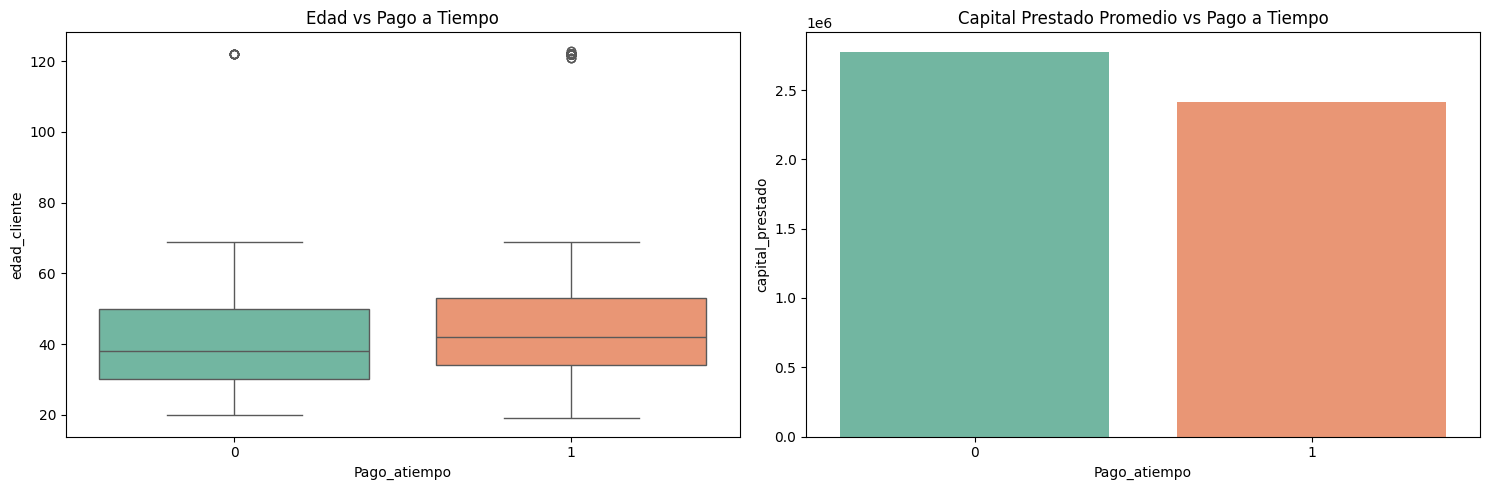

In [22]:
if 'Pago_atiempo' in df.columns:
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    
    sns.boxplot(x='Pago_atiempo', y='edad_cliente', data=df, ax=axes[0], palette='Set2')
    axes[0].set_title('Edad vs Pago a Tiempo')
    
    sns.barplot(x='Pago_atiempo', y='capital_prestado', data=df, errorbar=None, ax=axes[1], palette='Set2')
    axes[1].set_title('Capital Prestado Promedio vs Pago a Tiempo')
    
    plt.tight_layout()
    plt.show()


In [23]:
# Promedio de cada variable numérica según Pago_atiempo
cols_num_all = [c for c in df.select_dtypes(include='number').columns
                if c != 'Pago_atiempo' and not c.startswith('tipo_credito_')]
display(df.groupby('Pago_atiempo')[cols_num_all].mean().T.round(2))

Pago_atiempo,0,1
capital_prestado,2777162.69,2416629.60
plazo_meses,12.45,10.48
edad_cliente,41.62,44.05
salario_cliente,23503290.67,16867528.22
total_otros_prestamos,11567469.38,5940943.52
puntaje_datacredito,748.88,782.38
cant_creditosvigentes,5.58,5.74
huella_consulta,5.25,4.18
saldo_mora,0.04,0.00
saldo_total,39209.48,46272.26


## 9. Análisis Multivariado: Matriz de Correlación y Pairplots
Relaciones conjuntas entre múltiples variables.


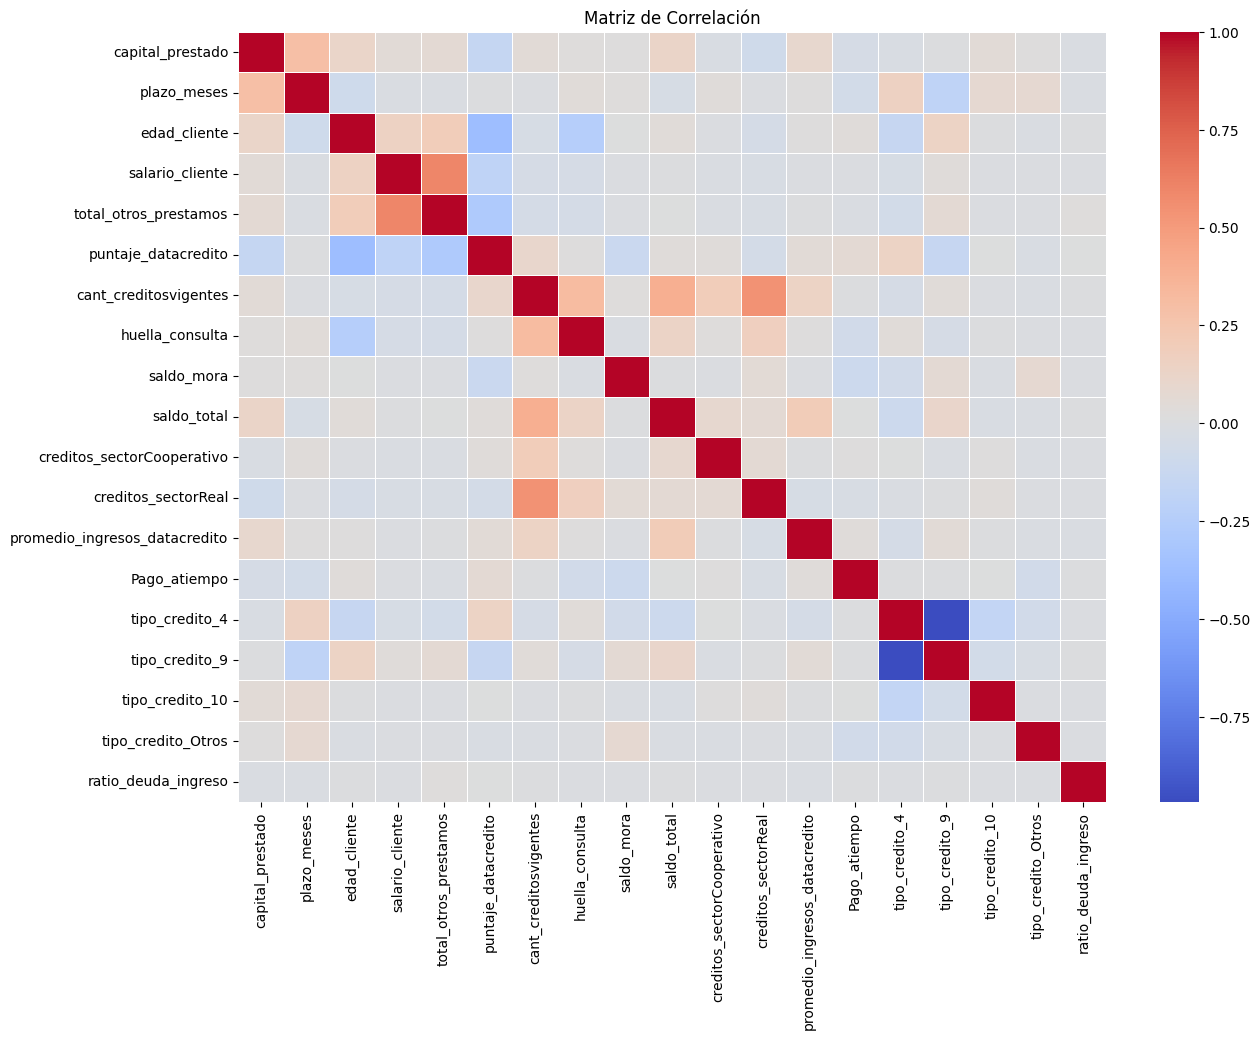

In [24]:
plt.figure(figsize=(14, 10))
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=False, cmap='coolwarm', linewidths=0.5)
plt.title('Matriz de Correlación')
plt.show()


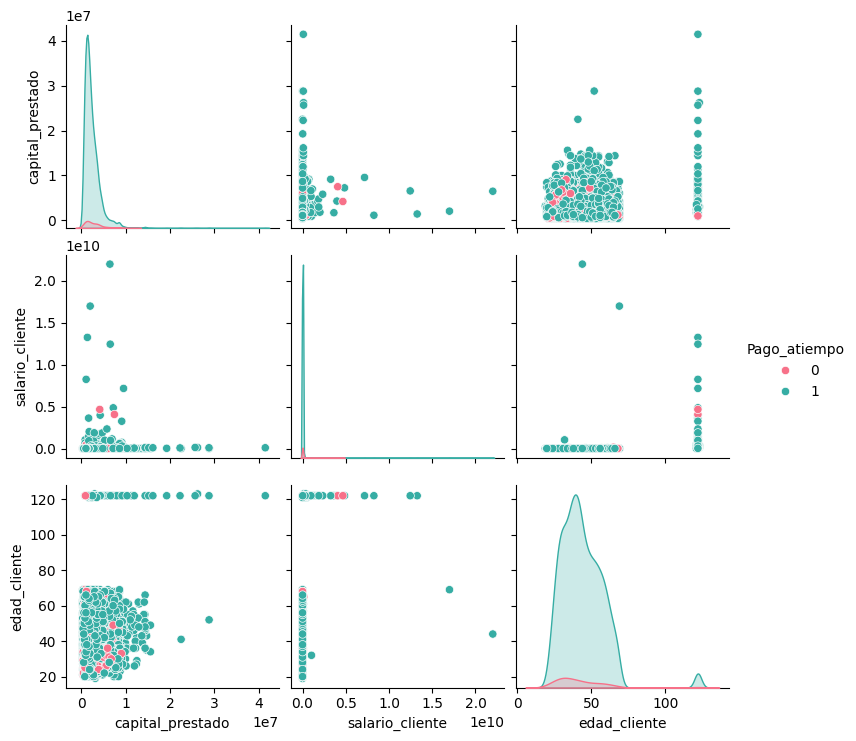

In [25]:
cols_pairplot = ['capital_prestado', 'salario_cliente', 'edad_cliente', 'Pago_atiempo']
if set(cols_pairplot).issubset(df.columns):
    sns.pairplot(df[cols_pairplot].dropna(), hue='Pago_atiempo', palette='husl', diag_kind='kde')
    plt.show()
